In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import acf, plot_acf, plot_pacf

# Aufgabe 1: CO<sub>2</sub> Monitoring

In [3]:
def plot_data(df: pd.DataFrame, lin: pd.Series = None) -> None:
    plt.figure(figsize=(20, 8))

    if lin is not None:
        plt.plot(df.index.year, df["value"], color="red")
        plt.plot(df.index.year, lin, color="orange", label="Linearer Trend")
        plt.ylabel(r"Log(CO$_2$(t) / CO$_2$(1969))")
        plt.legend()
    else:
        plt.plot(df["value"], color="red")
        plt.ylabel(r"CO$_2$")

    plt.title(r"Mauna Loa: CO$_2$-Werte")
    plt.xlabel("Datum")
    plt.grid(alpha=0.5)
    plt.margins(x=0)
    plt.show()

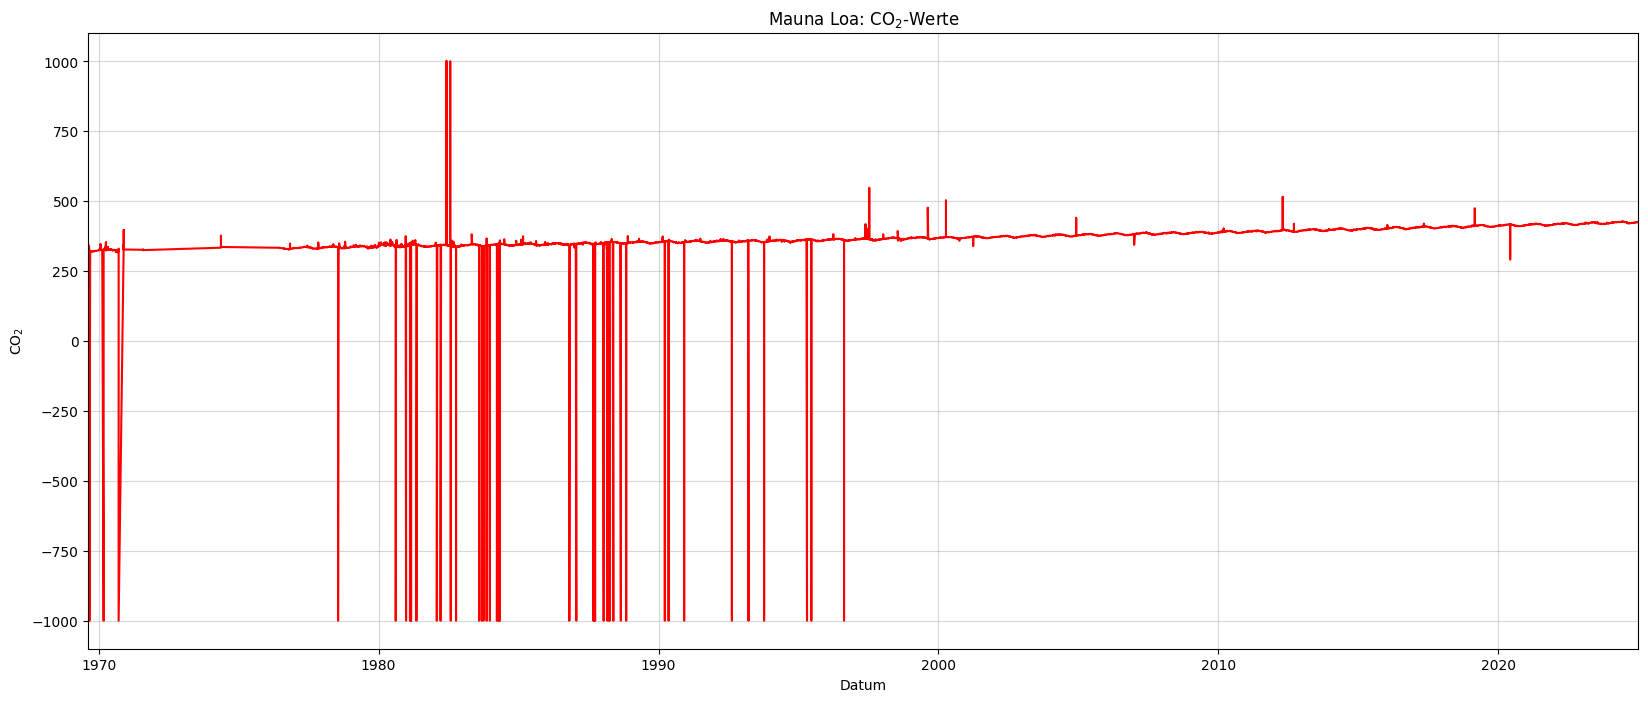

In [4]:
df = pd.read_csv("co2_mlo_surface-flask_1_ccgg_event.txt", sep=r"\s+", comment="#", header=0)
# display(df.dtypes)
# display(df)
df["datetime"] = pd.to_datetime(df["datetime"])
df = df.set_index("datetime")[["value"]].sort_index()

plot_data(df)

#### Behandlung von Lücken / fehlenden Werten

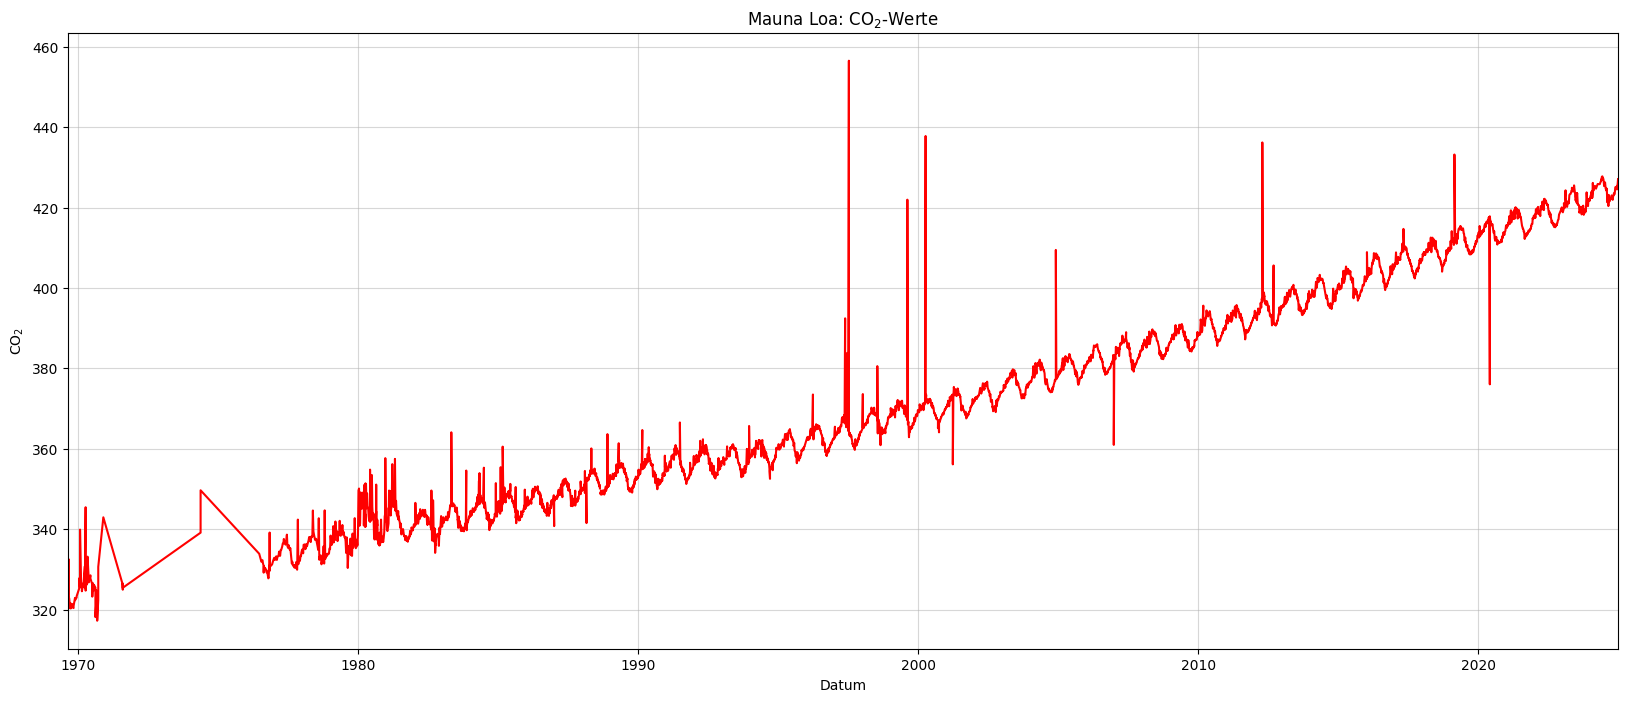

In [5]:
# Werte wie -999 und 1000 sind offensichtlich Messfehler, daher filtern
df[(df["value"] < -990) | (df["value"] > 990)] = None
# Mittelwert bei doppeltem Datum
df = df.groupby(level=0).mean()

plot_data(df)

Lücken der Zeitreihe:


,start,end,length
29,1971-08-03 20:30:00+00:00,1974-05-15 23:30:00+00:00,1016 days 03:00:00
30,1974-05-15 23:30:00+00:00,1976-06-18 20:00:00+00:00,764 days 20:30:00
28,1970-11-24 00:00:00+00:00,1971-08-03 20:30:00+00:00,252 days 20:30:00
27,1970-09-18 18:05:00+00:00,1970-11-24 00:00:00+00:00,66 days 05:55:00
9,1969-12-10 17:45:00+00:00,1970-01-12 20:35:00+00:00,33 days 02:50:00
2447,2022-11-22 20:18:00+00:00,2022-12-21 18:41:00+00:00,28 days 22:23:00
31,1976-06-18 20:00:00+00:00,1976-07-16 21:30:00+00:00,28 days 01:30:00
1046,1995-12-15 19:26:00+00:00,1996-01-12 20:15:00+00:00,28 days 00:49:00
20,1970-06-08 18:00:00+00:00,1970-07-03 00:15:00+00:00,24 days 06:15:00
19,1970-05-15 23:50:00+00:00,1970-06-08 18:00:00+00:00,23 days 18:10:00


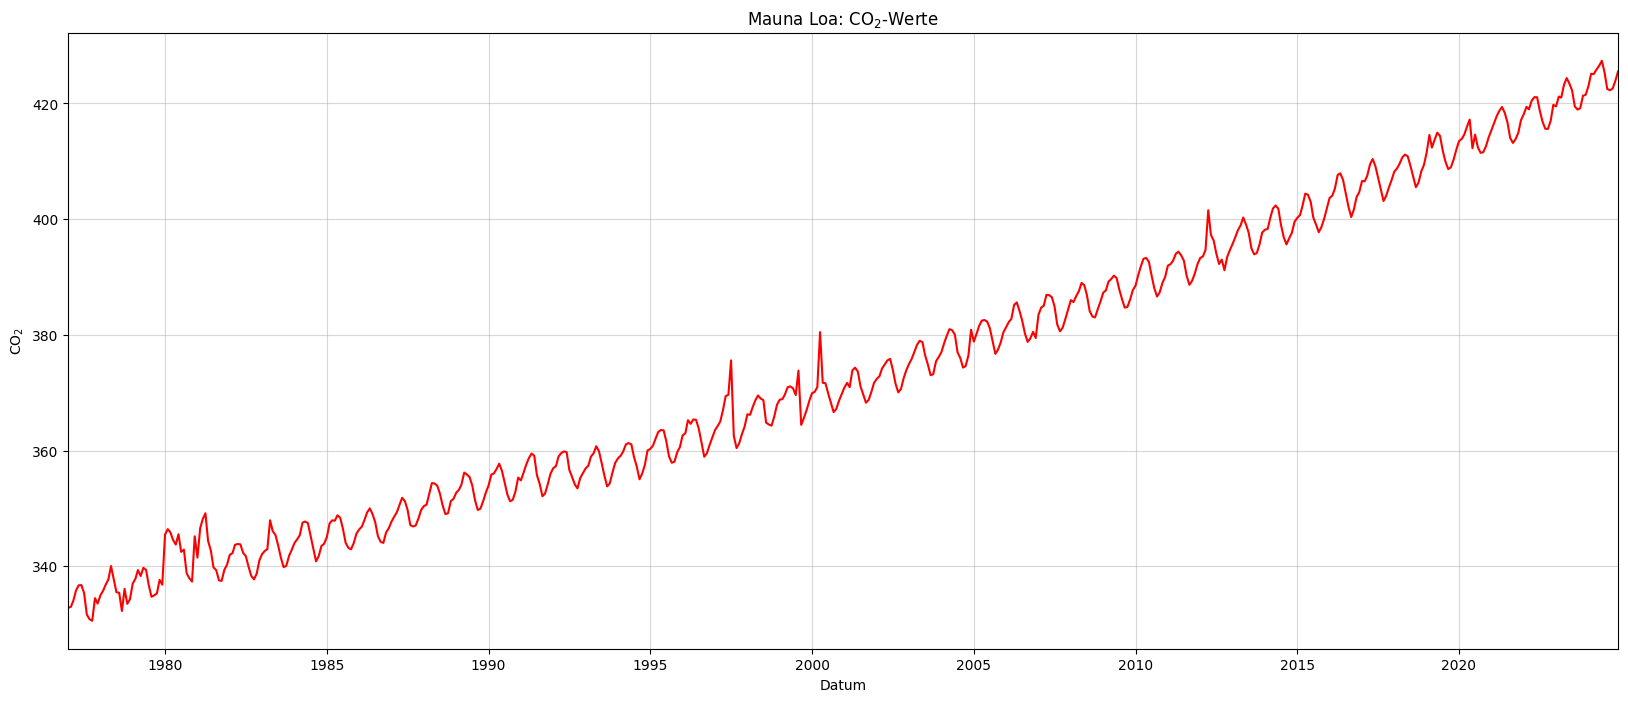

In [6]:
# Ausgabe der Lücken
series = df.index.to_series()
series = series.groupby(level=0).mean()

m = series.diff() > pd.Timedelta(days=1)

gaps = pd.DataFrame(
    {
        "start": series[m].shift(1),
        "end": series[m],
    }
)
gaps["length"] = gaps["end"] - gaps["start"]
gaps = gaps.reset_index(drop=True)

print("Lücken der Zeitreihe:")
display(gaps.sort_values(by="length", ascending=False).head(15))

# Für Quotienten Test
year_1969 = df.loc[: pd.to_datetime("1969-12-31 23:59:59+00:00")].copy().resample("YE").mean()

# Zuschneiden der Zeitreihe, übrige Lücken < 30 Tage
df = df.loc[pd.to_datetime("1977-01-01 20:00:00+00:00") :].copy()

# Monatliches Mittel zum Füllen der Lücken
df = df.resample("MS").mean()

plot_data(df)

#### Jährliches Mittel & Wachstumsrate

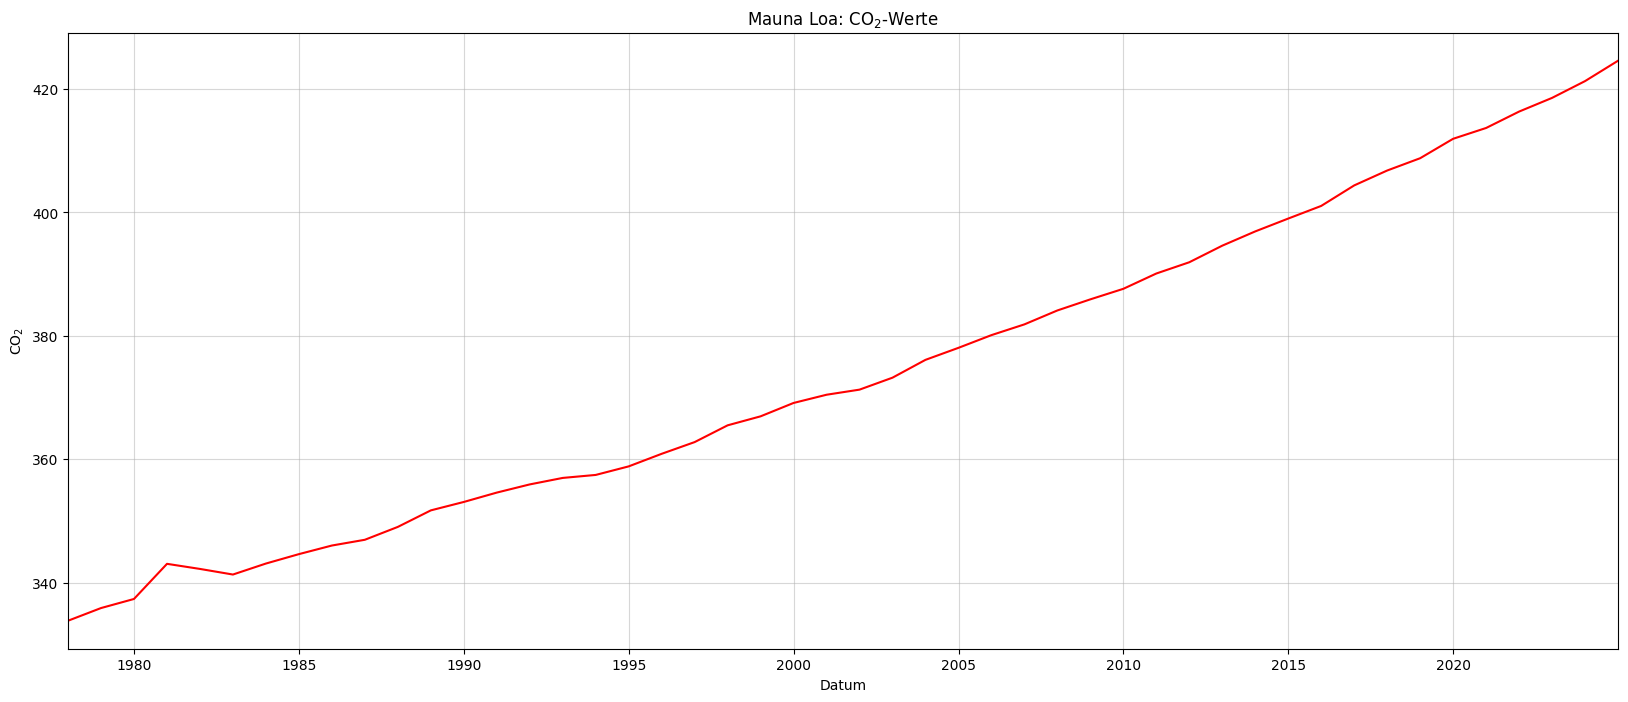

Global:


,count,mean,std,min,25%,50%,75%,max
value,48.0,374.278606,26.312451,333.811,352.721374,370.856516,395.187315,424.585809


Pro Jahrzehnt:


value                                                            \
         count        mean       std         min         25%         50%   
datetime                                                                   
1970       3.0  335.670493  1.770627  333.811000  334.837573  335.864146   
1980      10.0  346.092879  4.055423  341.297428  343.044131  345.302692   
1990      10.0  360.887967  5.000773  354.579079  357.079590  359.846172   
2000      10.0  378.864112  6.082492  370.443382  373.929260  379.076720   
2010      10.0  400.546017  7.346749  390.092760  395.187315  400.024031   
2020       5.0  418.890374  4.237595  413.685926  416.342177  418.559709   

                                  
                 75%         max  
datetime                          
1970      336.600240  337.336333  
1980      348.494968  353.062353  
1990      364.804606  369.108729  
2000      383.539601  387.613323  
2010      406.185107  411.928997  
2020      421.278247  424.585809

Jährliche Wachstumsrate in %:
	1980-1989: 0.3207
	2000-2009: 0.5047
	2010-2019: 0.607
	2020-2024: 0.6523



In [7]:
yearly = df.resample("YE").mean()

plot_data(yearly)

print("Global:")
display(yearly.describe().transpose())
print("Pro Jahrzehnt:")
display(yearly.groupby((yearly.index.year // 10) * 10).describe())

rate = {"1980-1989": 0, "2000-2009": 0, "2010-2019": 0, "2020-2024": 0}

for index, year in enumerate([(1980, 1989), (2000, 2009), (2010, 2019), (2020, 2024)]):
    start = yearly[yearly.index.year == year[0]].iloc[0, 0]
    end = yearly[yearly.index.year == year[1]].iloc[0, 0]
    # Berechnung jährlicher Wachstumsrate
    rate[list(rate.keys())[index]] = round(float((end / start) ** (1 / (year[1] - year[0])) - 1) * 100, 4)

print("Jährliche Wachstumsrate in %:")
string = ""
for key, val in rate.items():
    string = string + f"\t{key}: {val}\n"
print(string)

<font color="orange">
Die jährliche Wachstumsrate steigt kontinuierlich an. Die Zunahme scheint dabei nicht linear zu verlaufen, was auf eine beschleunigte Entwicklung der CO<sub>2</sub>-Werte hindeutet.
</font>

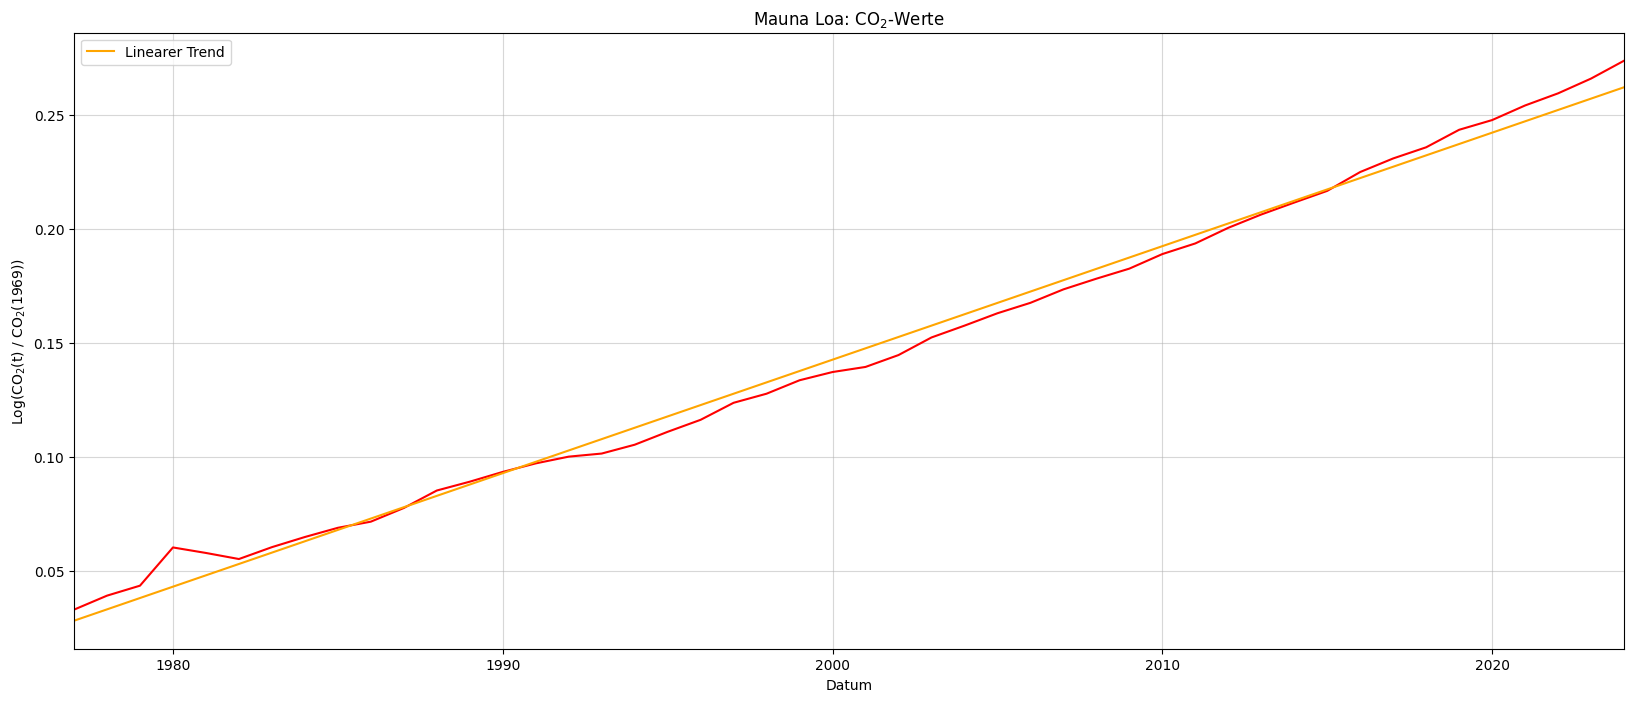

In [8]:
# Quotienten Test
log = np.log(yearly / year_1969.iloc[0, 0])

# Linearer Trend
z = np.polyfit(yearly.index.year, log["value"], 1)
p = np.poly1d(z)

plot_data(log, p(yearly.index.year))

<font color="orange">
Der Log-Plot verläuft sehr nahe des linearen Trends (mit leichten Abweichungen). Das deutet auf ein annähernd exponentielles Wachstum der CO<sub>2</sub>-Werte hin.
</font>

# Aufgabe 2: Zeitreihen Eigenschaften und Vorhersage

In [9]:
df = pd.read_csv("FreiburgNiederschlag.csv")
df["category"] = pd.to_datetime(df["category"], format="mixed")
df = df.rename(columns={"category": "date", "Niederschlag": "value"})
df = df.set_index("date").sort_index()

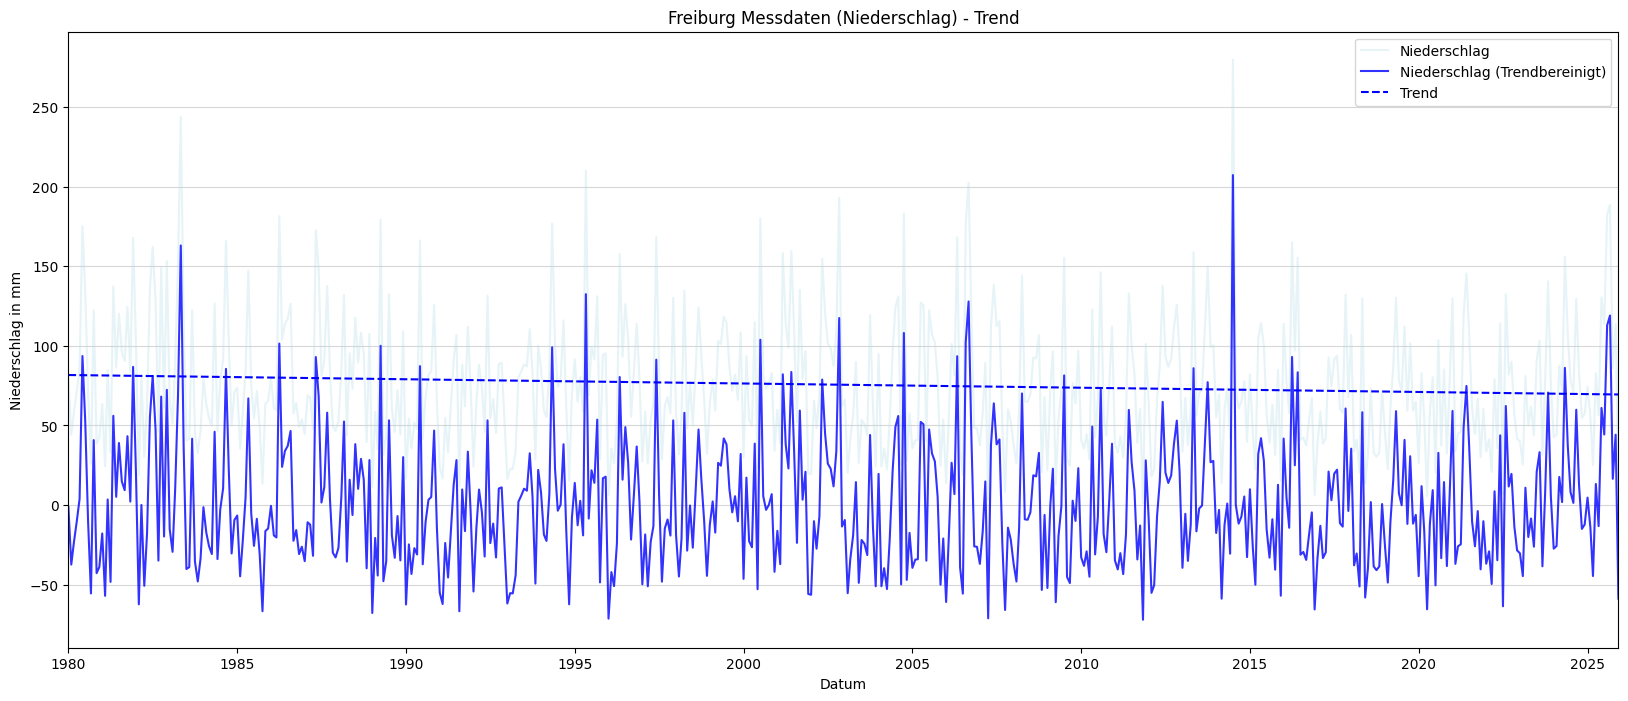

In [10]:
# Trend
x = mdates.date2num(df.index)
p = np.poly1d(np.polyfit(x, df["value"], 1))
df["trend"] = p(x)

df["detrended"] = df["value"] - df["trend"]

plt.figure(figsize=(20, 8))

plt.plot(df.index, df["value"], color="lightblue", alpha=0.3, label="Niederschlag")
plt.plot(df.index, df["detrended"], color="blue", alpha=0.8, label="Niederschlag (Trendbereinigt)")
plt.plot(df.index, df["trend"], color="blue", alpha=1, label="Trend", linestyle="--")

plt.title("Freiburg Messdaten (Niederschlag) - Trend")
plt.xlabel("Datum")
plt.ylabel("Niederschlag in mm")
plt.grid(axis="y", alpha=0.5)
plt.margins(x=0)
plt.legend()
plt.show()

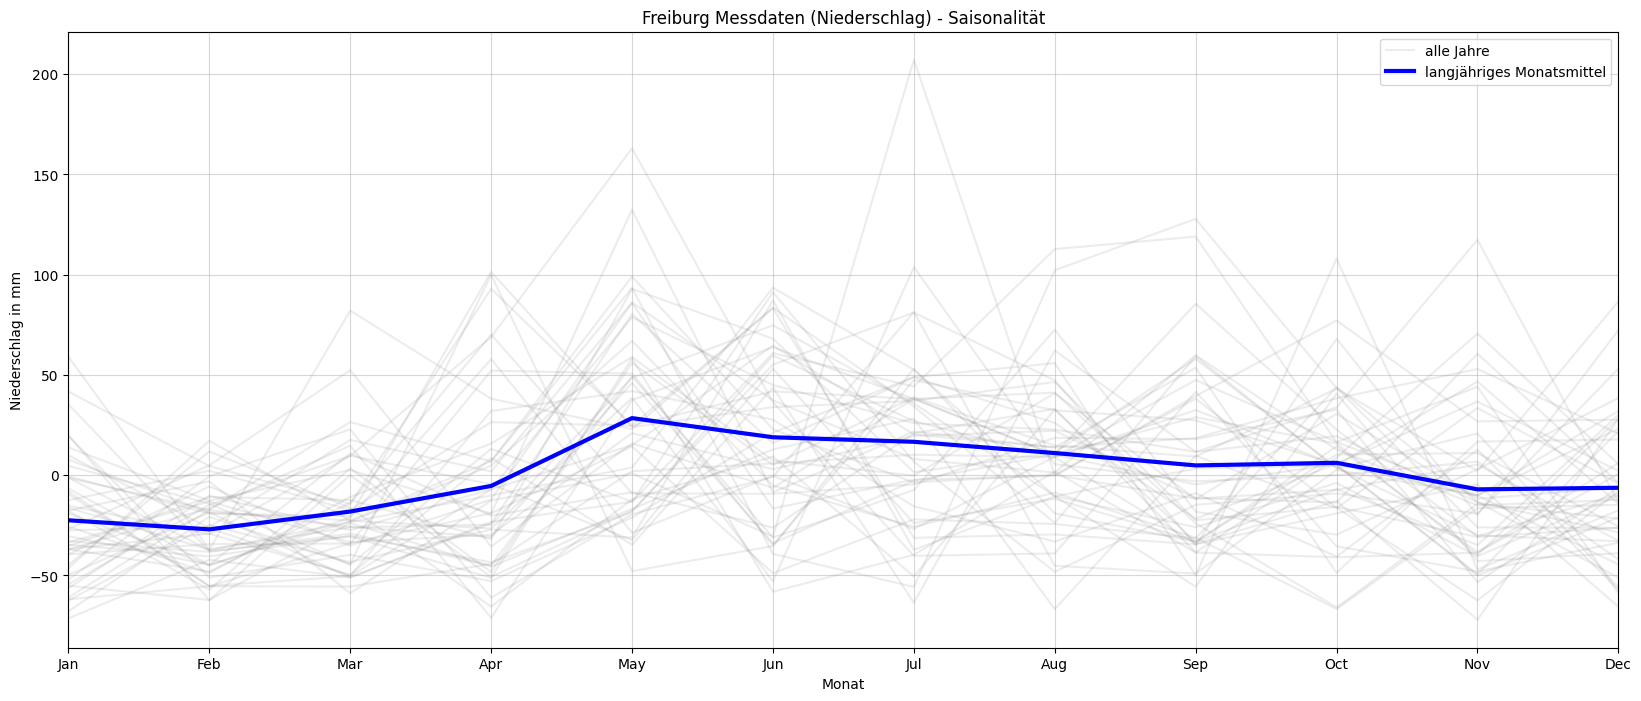

In [11]:
# Jährliche Saisonalität
df["month"] = df.index.month
df["year"] = df.index.year

seasonal = df.groupby("month")["detrended"].mean()

plt.figure(figsize=(20, 8))

for i, y in enumerate(df["year"].unique()):
    data = df[df["year"] == y]
    if i == 0:
        plt.plot(data["month"], data["detrended"], color="gray", alpha=0.15, label="alle Jahre")
    else:
        plt.plot(data["month"], data["detrended"], color="gray", alpha=0.15)
plt.plot(seasonal, color="blue", alpha=1, label="langjähriges Monatsmittel", linewidth=3)

plt.title("Freiburg Messdaten (Niederschlag) - Saisonalität")
plt.xlabel("Monat")
plt.ylabel("Niederschlag in mm")
plt.xticks(
    ticks=range(1, 13), labels=pd.Series(range(1, 13)).map(lambda x: pd.to_datetime(x, format="%m").strftime("%b"))
)
plt.grid(axis="both", alpha=0.5)
plt.margins(x=0)
plt.legend()
plt.show()

df = df.join(seasonal, on="month", rsuffix="_seasonal")

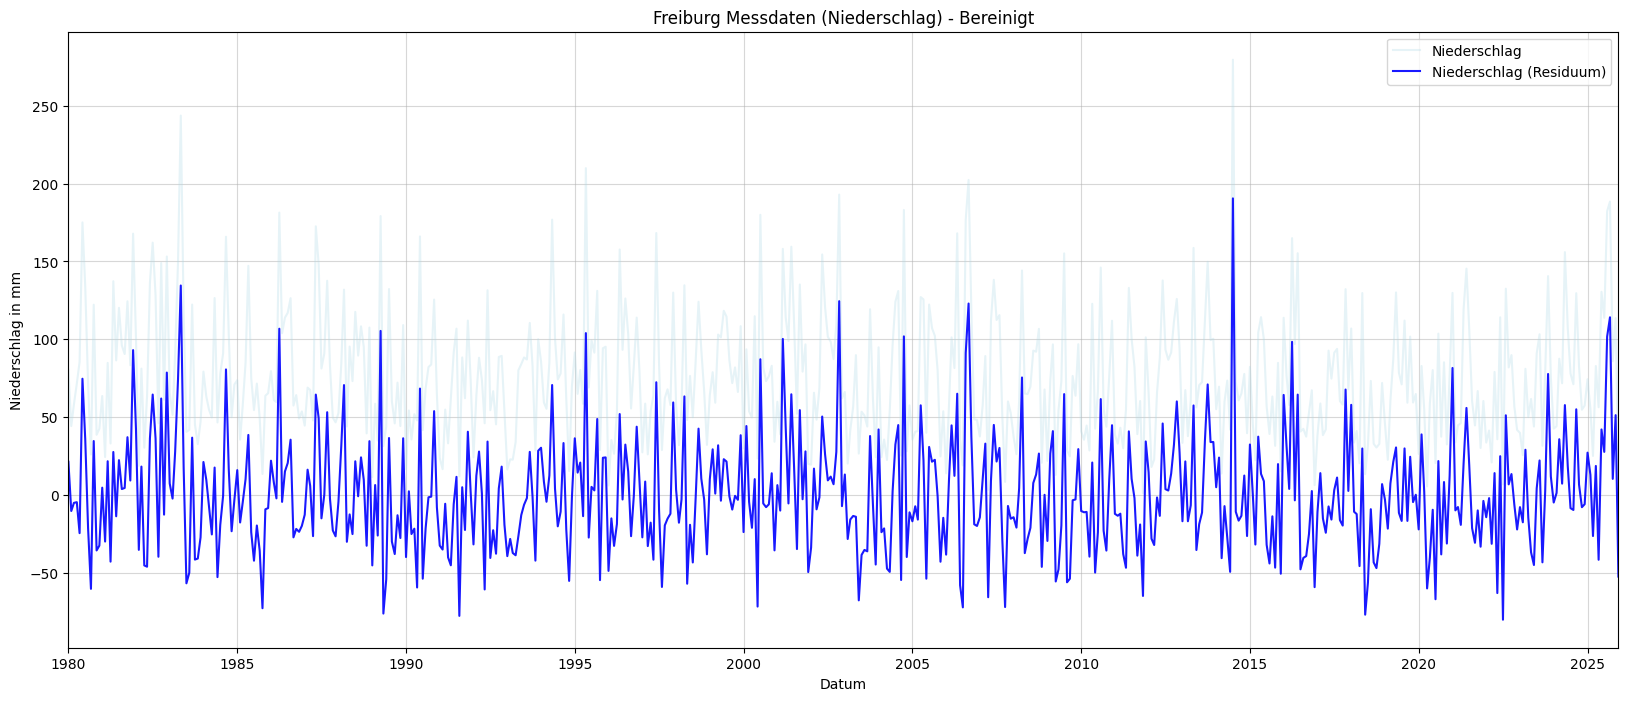

In [12]:
# Bereinigte Zeitreihe
df["resid"] = df["detrended"] - df["detrended_seasonal"]

plt.figure(figsize=(20, 8))

plt.plot(df.index, df["value"], color="lightblue", alpha=0.3, label="Niederschlag")
plt.plot(df.index, df["resid"], color="blue", alpha=0.9, label="Niederschlag (Residuum)")

plt.title("Freiburg Messdaten (Niederschlag) - Bereinigt")
plt.xlabel("Datum")
plt.ylabel("Niederschlag in mm")
plt.grid(axis="both", alpha=0.5)
plt.margins(x=0)
plt.legend()
plt.show()

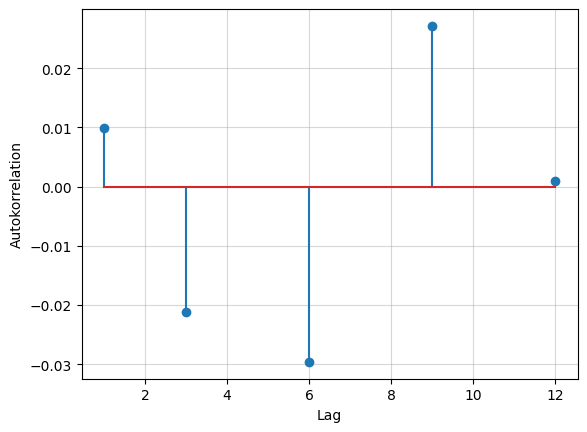

In [13]:
# Autokorrelation
vals = acf(df["resid"].dropna(), nlags=12)
lags = [1, 3, 6, 9, 12]

plt.stem(lags, [vals[lag] for lag in lags])
plt.xlabel("Lag")
plt.ylabel("Autokorrelation")
plt.grid(which="both", alpha=0.5)
plt.show()

<font color="orange">
Interpretation: Da hier -0,03 die betragsmäßig größte Autokorrelation bei den gewählten Lags ist, lässt das vermuten, dass die Zeitreihe nicht mehr signifikant autokorreliert, also stationär, ist.
</font>

In [14]:
import sklearn as sk
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [15]:
split_date = pd.to_datetime("2025-01-01")
train = df[df.index < split_date]
test = df[df.index >= split_date]

In [16]:
mean_model = train.copy()
mean_model["prediction"] = train.value.mean()
naive_model = train.copy()
naive_model["prediction"] = naive_model["value"].shift(1)
seasonal_naive_model = train.copy()
seasonal_naive_model["prediction"] = seasonal_naive_model["value"].shift(12)

In [17]:
exponential_smoothing_model = ExponentialSmoothing(train[["value"]], seasonal="add", seasonal_periods=12).fit(smoothing_level=0.5)
forecast = exponential_smoothing_model.forecast(len(test))

/Users/sebastianstrassner/Desktop/Klausur/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


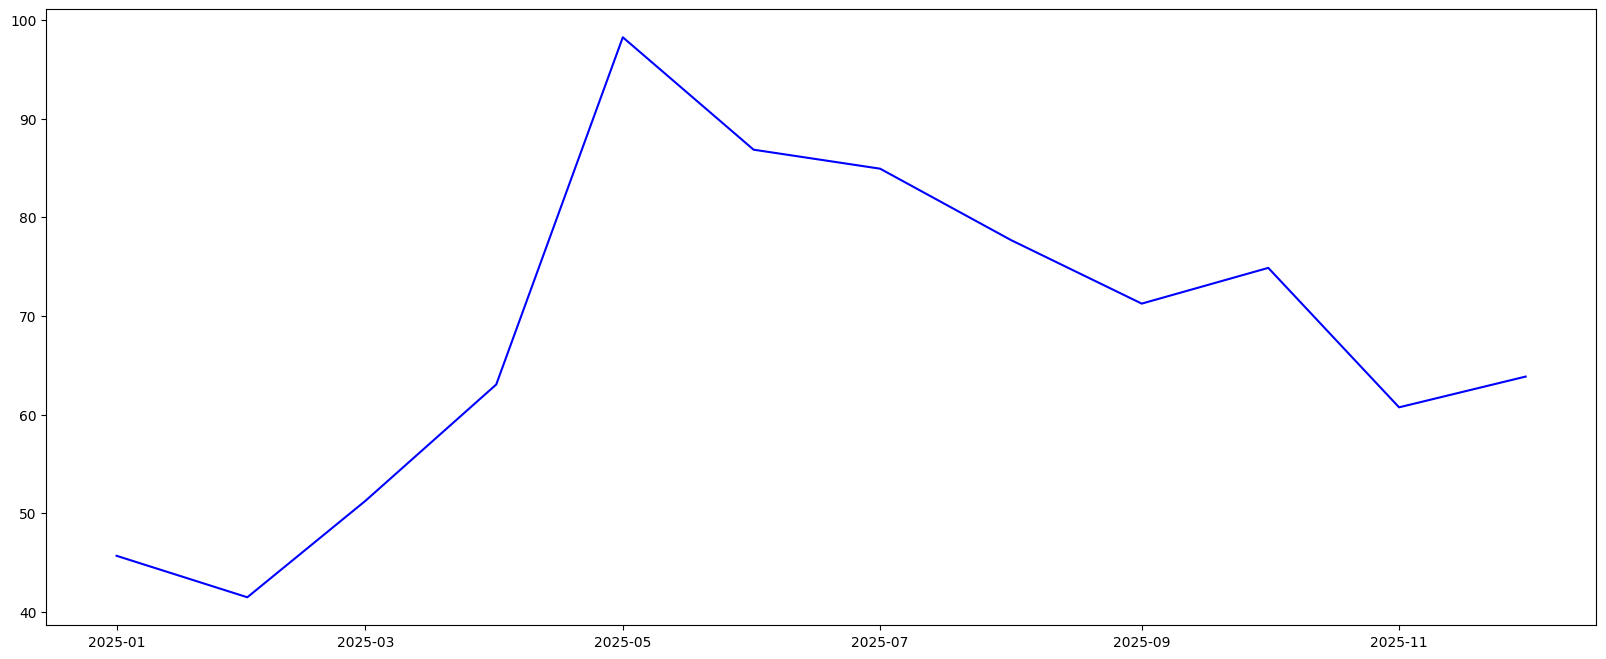

In [18]:
plot = plt.figure(figsize=(20, 8))
plt.plot(forecast, color="blue", label="Trainingsdaten")
plt.show(plot)